# Intermolecular interaction strengths

In [1]:
import pandas as pd
import re
from scipy.constants import Boltzmann as k_B, Avogadro as N_A
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

T = 2000             # Temperature in Kelvin
J_to_kcal = 1 / 4184 # Conversion: 1 J = 1/4184 kcal
kcal_per_kT = (k_B * T * N_A) * J_to_kcal # kcal/mol per kT

# Dict generated with ChatGPT in October 2025 - consider as rough estimate
data = {
    "Interaction Type": [
        "Covalent bond",
        "Ion–ion",
        "Transition metal–ligand (coordination)",
        "Metal–metal",
        "Ion–dipole",
        "Hydrogen bond",
        "Dispersion"
    ],
    "Typical Strength (kcal/mol)": [
        "50–200+",
        "40–100+",
        "10–100 (broad range)",
        "15–75",
        "10–50",
        "2–10",
        "0.5–2"
    ],
    "Examples": [
        "C–C (~85), H–H (~104), C=O (~170)",
        "Na⁺···Cl⁻ (~80), K⁺···O⁻",
        "Fe–N (heme), Pt–Cl",
        "Fe–Fe (~70), Cu–Cu (~50)",
        "Na⁺···H₂O (~15), Cl⁻···H₂O (~20)",
        "O–H···O (5), N–H···O (3–7)",
        "Ar···Ar (~0.3), benzene···benzene (~1–2)"
    ]
}

def extract_min_max(val):
    '''Function to extract min and max values from range strings'''
    # Remove non-numeric characters except decimal points, dash, and plus
    val = re.sub(r"[^\d\.\–+-]", "", val)
    val = val.replace("–", "-")  # Normalize dash
    parts = val.split('-')
    
    try:
        min_val = float(parts[0])
        max_part = parts[1]
        if '+' in max_part:
            max_val = float(max_part.replace('+', ''))  # assume it's a minimum, unbounded max
        else:
            max_val = float(max_part)
    except:
        min_val = max_val = None

    return pd.Series([min_val, max_val])

df = pd.DataFrame(data)
df[['Min (kcal/mol)', 'Max (kcal/mol)']] = df['Typical Strength (kcal/mol)'].apply(extract_min_max)
df["Avg (kcal/mol)"] = (df["Min (kcal/mol)"] + df["Max (kcal/mol)"]) / 2
df['Avg (kT)'] = (df['Avg (kcal/mol)'] / kcal_per_kT).round(1)
df.drop(columns=["Typical Strength (kcal/mol)"], inplace=True)
df

,Interaction Type,Examples,Min (kcal/mol),Max (kcal/mol),Avg (kcal/mol),Avg (kT)
0,Covalent bond,"C–C (~85), H–H (~104), C=O (~170)",50.0,200.0,125.00,31.5
1,Ion–ion,"Na⁺···Cl⁻ (~80), K⁺···O⁻",40.0,100.0,70.00,17.6
2,Transition metal–ligand (coordination),"Fe–N (heme), Pt–Cl",10.0,100.0,55.00,13.8
3,Metal–metal,"Fe–Fe (~70), Cu–Cu (~50)",15.0,75.0,45.00,11.3
4,Ion–dipole,"Na⁺···H₂O (~15), Cl⁻···H₂O (~20)",10.0,50.0,30.00,7.5
5,Hydrogen bond,"O–H···O (5), N–H···O (3–7)",2.0,10.0,6.00,1.5
6,Dispersion,"Ar···Ar (~0.3), benzene···benzene (~1–2)",0.5,2.0,1.25,0.3


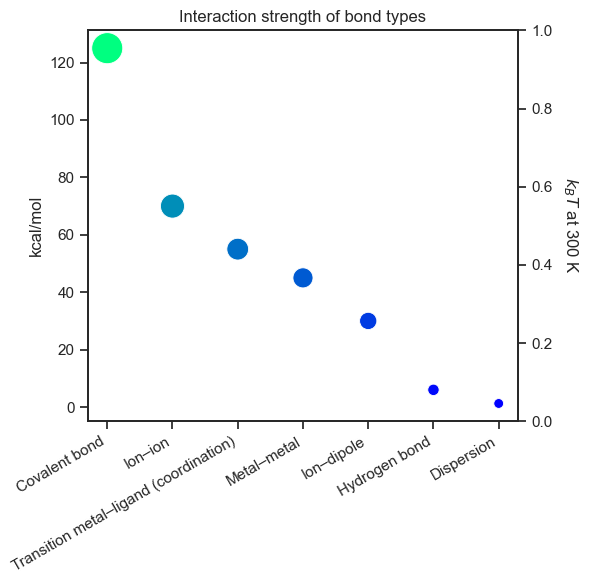

In [2]:
# Bubble plot — area ∝ strength
plt.figure(figsize=(6, 6))
sns.set(style="ticks")

# Normalize bubble size (area-based scaling)
size_factor = 500  # Adjust to scale bubbles nicely
ax1 = sns.scatterplot(
    x="Interaction Type",
    y="Avg (kcal/mol)",
    size="Avg (kcal/mol)",
    sizes=(50, size_factor),
    hue="Avg (kcal/mol)",
    data=df,
    palette="winter",
    legend=False
)
ax1.set_title("Interaction strength of bond types")
ax1.set_ylabel("kcal/mol")
ax1.set_xlabel("")
plt.setp(ax1.get_xticklabels(), rotation=30, ha='right')

# Secondary y-axis for kT scale
ax2 = ax1.twinx()
ylim_kcal = ax1.get_ylim()
ylim_kT = [y / kcal_per_kT for y in ylim_kcal]
ax2.set_ylabel(r"$k_BT$ at 300 K", rotation=270, labelpad=20)

plt.tight_layout()
plt.show();

## Average energy in Lennard-Jones system

We here calculate the _average energy per particle_ for a LJ system with a fixed number density, $\rho$.
We crudely assume that the system is unstructured, i.e. that $g(r)=1$ for all $r>\sigma$ or zero otherwise. The mean energy per particle is:
$$
U/N = \frac{1}{2}\cdot \int_0^{\infty} u(r) \cdot \underbrace{\overbrace{g(r)\rho}^{\rho(r)}\cdot 4\pi  r^2}_{N(r)} \cdot dr 
$$
We multiply by 1/2 to avoid double counting interactions. We assume a Lennard-Jones potential for the pair interaction between two argon atoms:
$$
u(r) = 4\epsilon \left [ \left (  \frac{\sigma}{r}  \right )^{12}
- \left (  \frac{\sigma}{r}  \right )^6
\right ]
$$

In [17]:
from scipy.integrate import quad # used for numerical integration

epsilon = 4.0  # Depth of potential well, kJ/mol
sigma = 3.5    # Finite distance at which the potential is zero, ~diameter (Å)
rho = 0.02     # Number density in 1/Å3

def u(r):
    '''Lennard Jones potential energy (in same units as epsilon)'''
    return 4 * epsilon * ((sigma / r)**12 - (sigma / r)**6)

def g(r):
    '''Radial distribution function, g(r)'''
    if r < sigma:
        return 0
    else:
        return 1

def integrand(r):
    return u(r) * g(r) * r**2

U_avg = 2 * np.pi * rho * quad(integrand, 0, np.inf)[0]
print(f"Average interaction energy per molecule: {U_avg:.1f} kJ/mol")

Average interaction energy per molecule: -19.2 kJ/mol


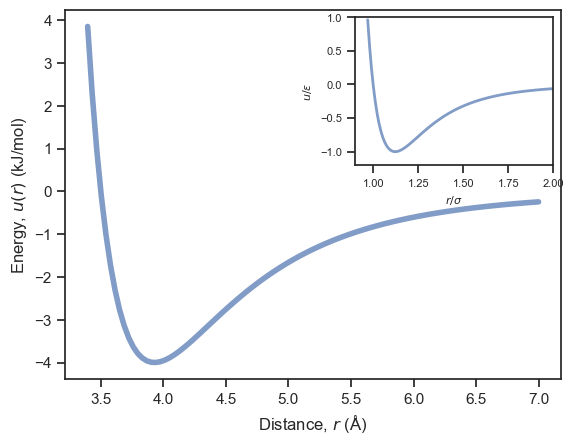

In [15]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

r = np.linspace(0.97 * sigma, 2 * sigma, 100)
plt.plot(r, np.vectorize(u)(r), lw=4, alpha=0.7)
plt.xlabel(r"Distance, $r$ (Å)")
plt.ylabel(r"Energy, $u(r)$ (kJ/mol)")

# Plot inset
ax_inset = inset_axes(plt.gca(), width="40%", height="40%", loc="upper right")
ax_inset.plot(r / sigma, np.vectorize(u)(r) / epsilon, lw=2, alpha=0.7)
ax_inset.set_xlabel(r"$r/\sigma$", fontsize=8)
ax_inset.set_ylabel(r"$u/\epsilon$", fontsize=8)
ax_inset.tick_params(axis='both', which='major', labelsize=8)

# Optional: adjust limits for clarity
ax_inset.set_xlim(0.9, 2.0)
ax_inset.set_ylim(-1.2, 1)

plt.show()